In [1]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path(".").resolve()
sys.path.insert(0, str(NOTEBOOK_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from batch_mixing.config import (
    ANNDATA_IN, RESULTS_DIR, COL_PLATE, COL_CELLTYPE,
    CELLTYPE_A, CELLTYPE_B,
    RARE_FRACTIONS, N_TOTAL_LIST, RARE_DISTRIBUTIONS,
    N_PLATES_RARE, N_ITERATIONS_RARE,
)
from batch_mixing.data import load_data, subsample_rare, filter_proteins
from batch_mixing.correction import impute_rowmean, remove_plate_effect
from batch_mixing.embedding import run_pca
from batch_mixing.pipeline import run_rare_cell_simulation
from batch_mixing.visualization import (
    plot_rare_pca,
    plot_rare_fraction_curves,
    plot_rare_metric_heatmap,
    plot_distribution_impact,
)

RESULTS_DIR = Path("/home/sam/SCI/SCI/Data/batch_mixing")
RARE_DIR    = RESULTS_DIR / "rare_cell"

print("Imports OK")
print(f"Rare fraction grid : {RARE_FRACTIONS}")
print(f"n_total grid       : {N_TOTAL_LIST}")
print(f"Distributions      : {RARE_DISTRIBUTIONS}")
print(f"Iterations         : {N_ITERATIONS_RARE} per condition")

/home/sam/miniconda3/envs/sci_environment/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK
Rare fraction grid : [0.02, 0.05, 0.1, 0.15, 0.2]
n_total grid       : [50, 100, 200, 500]
Distributions      : ['uniform', 'random', 'clustered_2plates']
Iterations         : 50 per condition


In [36]:
ANNDATA_IN = Path("/home/sam/SCI/SCI/Data/AnnData/out")
adata      = load_data(ANNDATA_IN / "adata_protein.h5ad")
all_plates = sorted(adata.obs[COL_PLATE].unique().tolist())

print(f"\nAll plates ({len(all_plates)}): {all_plates}")
print(f"Total cells available per type:")
print(adata.obs[COL_CELLTYPE].value_counts().to_string())

Outlier filter   : 3114 -> 2266 cells (848 removed)
Condition filter : 1864 cells kept (['HEK293T', 'K562'])

Loaded : 1864 cells x 7231 proteins
Cell types : {'K562': 933, 'HEK293T': 931}
Plates     : {'Astral_5': 214, 'Astral_3': 214, 'timsTOF_2': 212, 'Astral_1': 210, 'timsTOF_1': 208, 'Astral_2': 208, 'Astral_4': 202, 'timsTOF_3': 201, 'Astral_6': 195}


All plates (9): ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']
Total cells available per type:
source name
K562       933
HEK293T    931


In [39]:
import anndata
adata    = anndata.read_h5ad(ANNDATA_IN / "adata_protein.h5ad")

In [41]:
adata.obs['source name'].unique()

array(['K562', 'HEK293T', 'Cellenone blank', 'QC - Hela',
       'Processing control', 'Site specific QC', 'Site specific blanks',
       'Sorting control'], dtype=object)

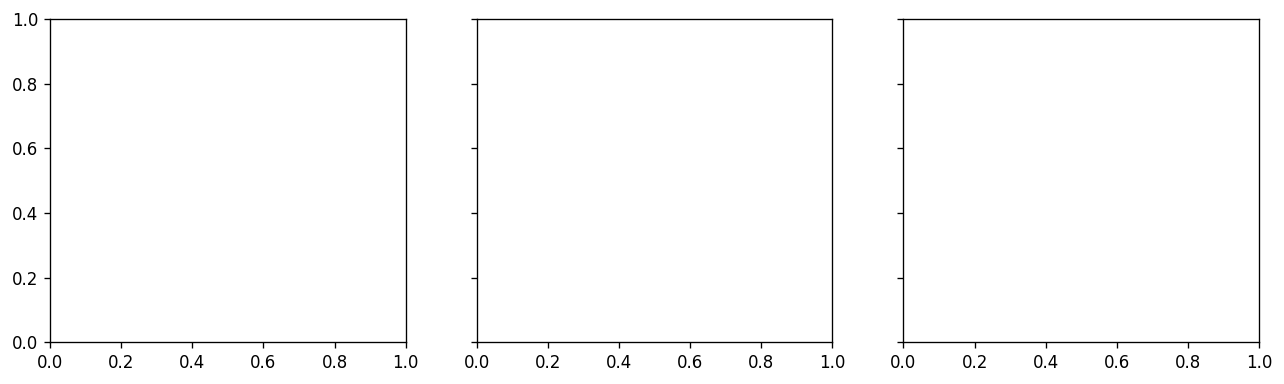

In [3]:
from batch_mixing.data import subsample_rare, filter_proteins

rng       = np.random.default_rng(0)
n_total   = 200
rare_frac = 0.10
n_rare    = int(n_total * rare_frac)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
dist_colours = {"uniform": "#4878D0", "random": "#EE854A", "clustered_2plates": "#d62728"}

In [24]:
n_total   = 200
rare_frac = 0.10
adata_sub = subsample_rare(
    adata, n_total=900, rare_fraction=rare_frac,
    distribution='clustered_2plates', all_plates=all_plates, rng=np.random.default_rng(0)
)

In [25]:
adata_sub.obs.groupby('plate_idx')['source name'].value_counts()

plate_idx  source name
Astral_1   HEK293T        90
           K562           45
Astral_2   HEK293T        90
Astral_3   HEK293T        90
Astral_4   HEK293T        90
Astral_5   HEK293T        90
           K562           45
Astral_6   HEK293T        90
timsTOF_1  HEK293T        90
timsTOF_2  HEK293T        90
timsTOF_3  HEK293T        90
Name: count, dtype: int64

In [27]:
adata

AnnData object with n_obs × n_vars = 1864 × 7231
    obs: 'sample_name', 'plate_id', 'plate_idx', 'source name', 'comment[X position]', 'comment[Y position]', 'comment[Plate Number]', 'comment[Gradient time]', 'comment[thawing timepoint]', 'comment[plate arrival]', 'injection_order', 'institute_name', 'Reinjection', 'Diameter', 'Elongation', 'Circularity', 'Doublet', 'Dividing', 'Dying', 'CellInBlank', 'comment[plate arrival]_date', 'comment[plate arrival]_time', 'comment[plate arrival]_datetime', 'comment[Gradient time]_date', 'comment[Gradient time]_time', 'comment[Gradient time]_datetime', 'instrument_type', 'n_proteins_withCont', 'n_proteins', 'pct_contaminant', 'completeness_sample_SC', 'completeness_sample_QC', 'completeness_outlier'
    var: 'PG.ProteinAccessions', 'PEP.StrippedSequence', 'PEP.IsProteotypic', 'EG.ModifiedSequence', 'FG.Charge', 'FG.LabeledSequence', 'FG.PrecursorIon', 'PG.Pvalue', 'PG.Qvalue', 'FG.Qvalue', 'EG.GlobalPrecursorQvalue', 'PG.Cscore', 'EG.ApexRT', 'E

Pre-flight: n_total=500, rare_fraction=30%

  uniform
    n_rare=150  proteins=1699
    kNN purity  corr=0.862  raw=0.409
    ARI         corr=0.910



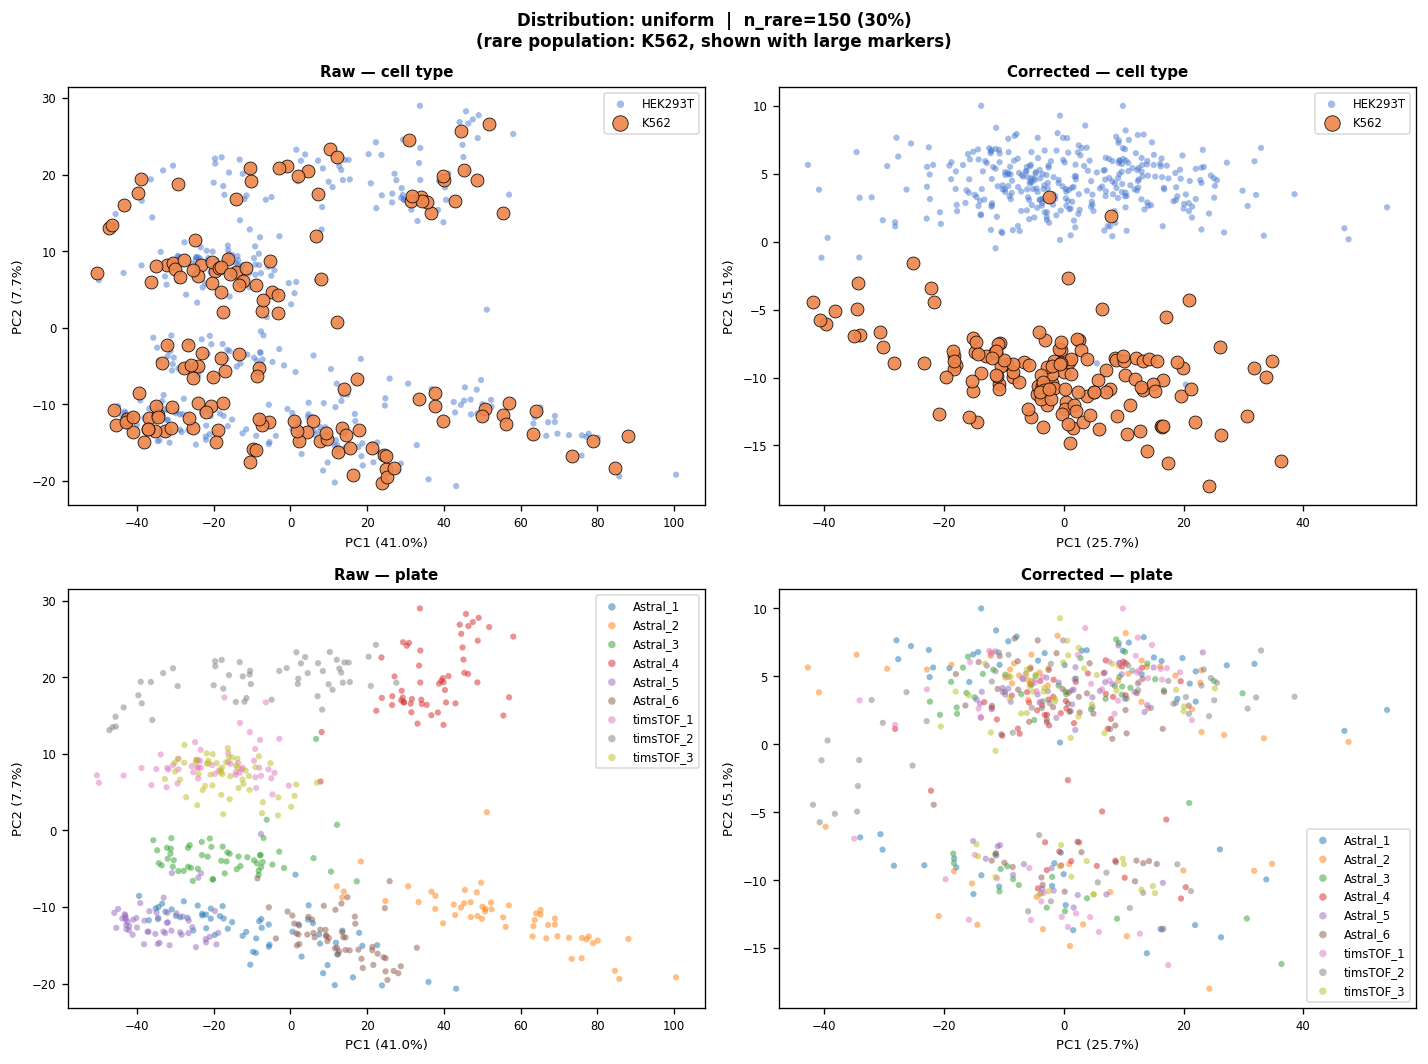

  random
    n_rare=150  proteins=1712
    kNN purity  corr=0.890  raw=0.432
    ARI         corr=0.967



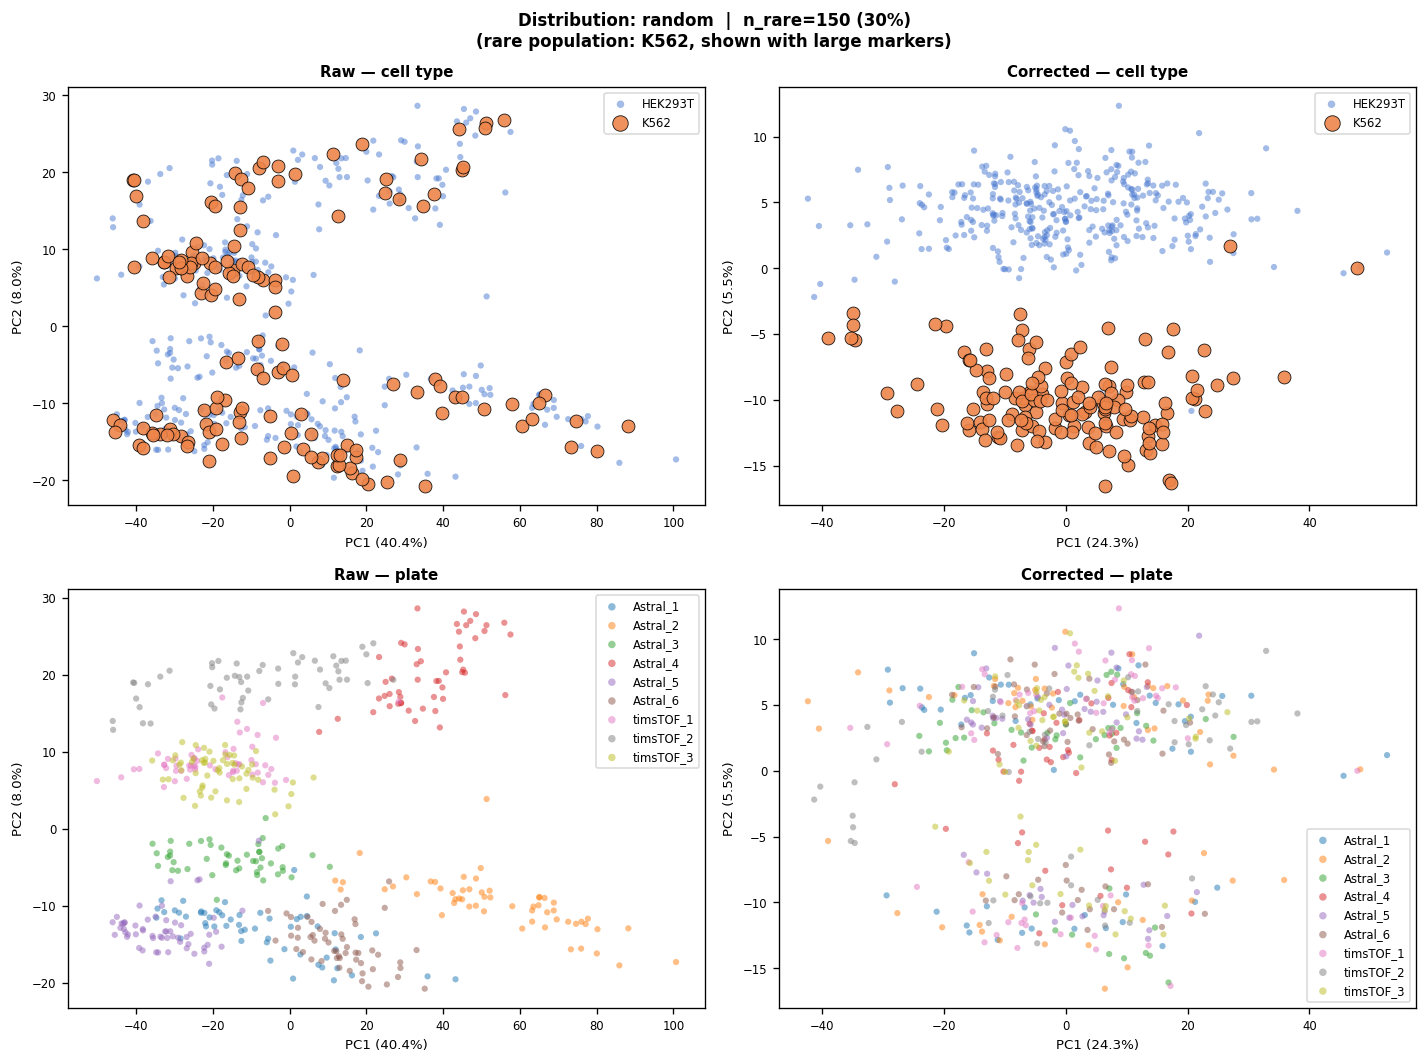

  clustered_2plates
    n_rare=150  proteins=1720
    kNN purity  corr=0.589  raw=0.902
    ARI         corr=0.076



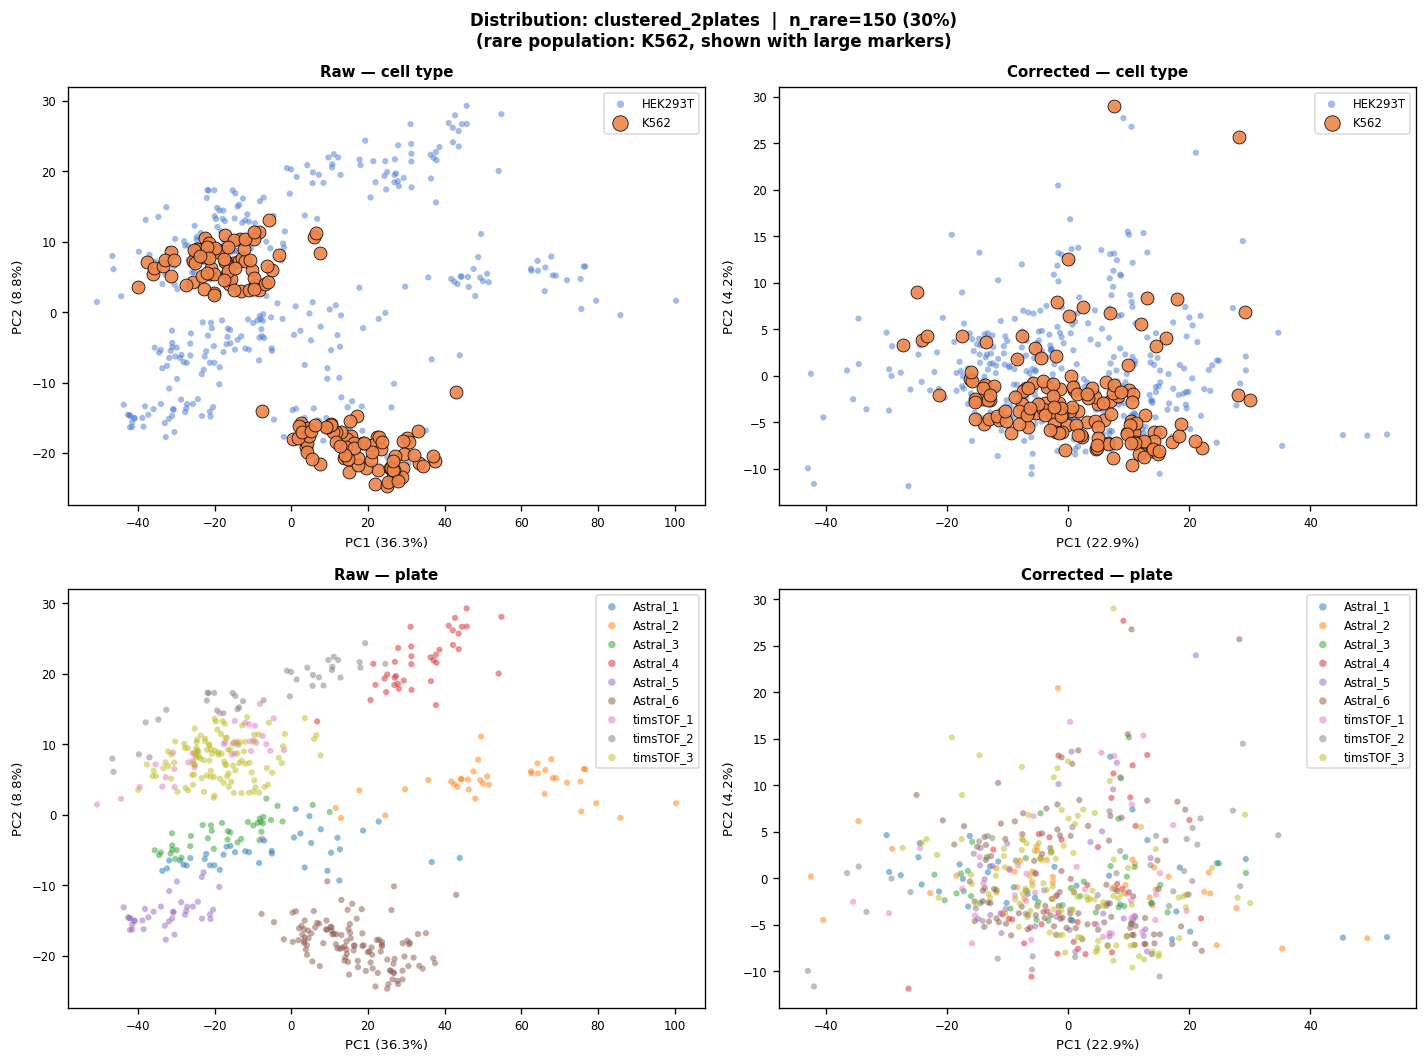

In [32]:
from batch_mixing.metrics import compute_knn_purity, compute_clustering

PREFLIGHT_N_TOTAL   = 500
PREFLIGHT_RARE_FRAC = 0.30

print(f"Pre-flight: n_total={PREFLIGHT_N_TOTAL}, rare_fraction={PREFLIGHT_RARE_FRAC:.0%}\n")

for dist in RARE_DISTRIBUTIONS:
    rng      = np.random.default_rng(42)
    adata_s  = subsample_rare(
        adata, PREFLIGHT_N_TOTAL, PREFLIGHT_RARE_FRAC,
        dist, all_plates, rng
    )
    if adata_s is None:
        print(f"  {dist}: SKIP (not enough cells)")
        continue

    adata_f       = filter_proteins(adata_s)
    ct_labels     = adata_f.obs[COL_CELLTYPE].values
    plate_labels  = adata_f.obs[COL_PLATE].values
    X_raw         = np.array(adata_f.X, dtype=float)
    X_raw_imp     = impute_rowmean(X_raw)
    X_corr, _     = remove_plate_effect(X_raw, plate_labels)
    pcs_raw,  ver = run_pca(X_raw_imp)
    pcs_corr, vec = run_pca(X_corr)

    knn_corr = compute_knn_purity(pcs_corr, ct_labels, CELLTYPE_B)
    knn_raw  = compute_knn_purity(pcs_raw,  ct_labels, CELLTYPE_B)
    ari_corr = compute_clustering(pcs_corr, ct_labels)["ari"]
    n_rare   = int((ct_labels == CELLTYPE_B).sum())

    print(f"  {dist}")
    print(f"    n_rare={n_rare}  proteins={adata_f.n_vars}")
    print(f"    kNN purity  corr={knn_corr:.3f}  raw={knn_raw:.3f}")
    print(f"    ARI         corr={ari_corr:.3f}\n")

    fig = plot_rare_pca(
        pcs_raw, pcs_corr, ct_labels, plate_labels, ver, vec,
        rare_label=CELLTYPE_B,
        title=f"Distribution: {dist}  |  n_rare={n_rare} ({PREFLIGHT_RARE_FRAC:.0%})",
    )
    plt.show()